In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob, os, shutil, cv2, json, sys
from tqdm import tqdm
from pathlib import Path

sys.path.append('../..')
from Dataset.index import VOLUMES, Normalization, PatchAssembler, TilesBuilder, getFiles, setFolder, showTile

In [83]:
BASE_PATH = f'../Dataset/{Path().resolve().name}'
BASE_PATH

'../Dataset/f3'

In [84]:
OPTIONS = json.loads(open('../../Task/info.json', 'r').read())
OPTIONS['dataset'] = BASE_PATH.split('/')[-1].strip()
OPTIONS

{'network': 'dbrnet',
 'dataset': 'f3',
 'img_size': [4, 128, 128],
 'step': 3,
 'scaling': None,
 'multiclass': True,
 'lr': 0.0001,
 'loss': 'dice_focal',
 'batch_size': 2,
 'scheduler': 'plateau',
 'dropout': 0.05,
 'num_filters': 32,
 'ema': True,
 'amp': True,
 'epochs': 200,
 'patience': 20,
 'n_trials': 1,
 'trial': 0}

In [85]:
with open('../../Task/info.json', 'w', encoding='utf-8') as file:
    json.dump(OPTIONS, file, ensure_ascii=False, indent=4)

# REMONTANDO O VOLUME

- Os dados brutos do F3 são patches `patch_dDDDD_hHHHH_wWWWW.dat` (float32 `(4, 64, 64)` = `(inline, z, xline)`, já em [0, 1]) em `files/seismics/` e `files/masks/` (o rótulo float com as classes 0–5, com o mesmo nome).
- Os patches se sobrepõem pela metade: o patch `i` de um eixo começa em `i × (2, 32, 32)`, e o último encosta no fim do volume (o `PatchAssembler` acha o início dele pela sobreposição com o penúltimo).
- Treinar nos patches como vêm vazaria o teste no treino (cada voxel está em até 8 patches) e não deixaria inline de fora para o `3 - Predict`: por isso o volume é remontado e cortado como o do `marlim`, um bloco de inlines a cada `step`.
- A remontagem tem que fechar com `diff` 0, `mismatch` 0 e `missing` 0 (toda sobreposição repete o mesmo dado e nenhum voxel fica vazio).
- O volume vai para `files/` com os nomes do `VOLUMES['f3']` (`Dataset/index.py`), que o `3 - Predict` lê; existindo, a remontagem é pulada.

In [86]:
RAW_DIR      = 'files/'
SEISMIC_PATH, MASK_PATH = [os.path.join(RAW_DIR, name) for name in VOLUMES[OPTIONS['dataset']]]

if not (os.path.exists(SEISMIC_PATH) and os.path.exists(MASK_PATH)):
    assembler = PatchAssembler(os.path.join(RAW_DIR, 'seismics'), os.path.join(RAW_DIR, 'masks'), size=(4, 64, 64), stride=(2, 32, 32))
    print(assembler)

    seismic, masks = assembler.build()
    if assembler.diff or assembler.mismatch or assembler.missing:
        raise ValueError(f'remontagem inconsistente: diff={assembler.diff}, mismatch={assembler.mismatch}, missing={assembler.missing}')

    np.save(SEISMIC_PATH, seismic)
    np.save(MASK_PATH, masks)
    print(f'diff {assembler.diff} | mismatch {assembler.mismatch} | missing {assembler.missing}')

print(SEISMIC_PATH, MASK_PATH)

files/f3_seismic.npy files/f3_masks.npy


# CARREGANDO O VOLUME

In [87]:
IMG_SIZE = tuple(OPTIONS['img_size'])
STEP     = OPTIONS.get('step', 3)

seismic = np.load(SEISMIC_PATH, mmap_mode='r')
masks   = np.load(MASK_PATH,    mmap_mode='r')

n_classes = int(np.max(masks)) + 1
print(seismic.shape, seismic.dtype, '| classes:', n_classes, '| tile:', IMG_SIZE, '| step:', STEP)

(601, 255, 901) float32 | classes: 6 | tile: (4, 128, 128) | step: 3


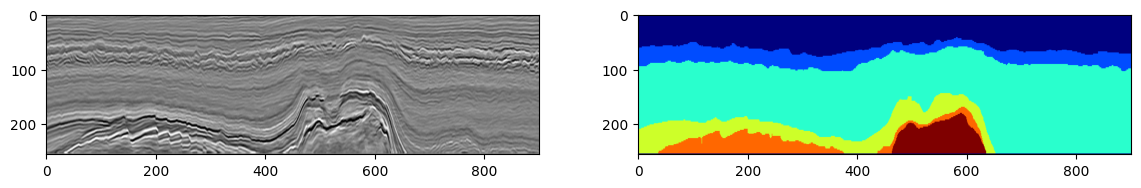

In [88]:
i = seismic.shape[0] // 2
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(np.asarray(seismic[i]), cmap='gray', vmin=0, vmax=1)
ax[1].imshow(np.asarray(masks[i]), cmap='jet', vmin=0, vmax=n_classes - 1)
plt.show()

### NORMALIZAÇÃO

- `scaling` do `info.json` escolhe o escalonamento da `Normalization` (`Dataset/index.py`); sem a chave é `'percentile'`.
- `'percentile'`: o volume como vem dos patches, já em [0, 1]; o tile passa como está.
- `'normalize'`: min-max de cada tile para [0, 1].
- `'standardize'`: padronização de cada tile (média 0, desvio 1), o passo da seção 3.2 do artigo da ResACEUnet.
- `null`: nenhum tratamento, o dado como vem (o caso do F3, cujos patches já chegam prontos); vai como célula vazia na coluna `scaling`.
- O `3 - Predict` aplica a mesma `Normalization` em cada bloco do volume inteiro.
- A escolha vai para a coluna `scaling` do `DataBase.csv`; o `index.py` refaz o `Format` quando a rodada pede outro.

In [89]:
SCALING   = OPTIONS.get('scaling', Normalization.DEFAULT)
normalize = Normalization(SCALING)
print(normalize)

Normalization(None): sem nenhum tratamento, o dado como vem


# TILES

In [90]:
tiles = TilesBuilder(IMG_SIZE, STEP, normalize)
rows  = tiles.build(seismic, masks)
print(len(rows), 'tiles')

100%|██████████| 51/51 [00:02<00:00, 21.61it/s]

816 tiles


In [91]:
df = pd.DataFrame(rows)
df.to_csv('DataBase.csv', index=None)
df

,img_path,mask_path,shape,min,max,mean,std,msk_max,step,scaling
0,/home/grva-mint/Projects/Facies/Dataset/f3/til...,/home/grva-mint/Projects/Facies/Dataset/f3/til...,"(4, 128, 128)",0.000000,1.000000,0.497390,0.087186,2,3,None
1,/home/grva-mint/Projects/Facies/Dataset/f3/til...,/home/grva-mint/Projects/Facies/Dataset/f3/til...,"(4, 128, 128)",0.000000,1.000000,0.497867,0.111160,2,3,None
2,/home/grva-mint/Projects/Facies/Dataset/f3/til...,/home/grva-mint/Projects/Facies/Dataset/f3/til...,"(4, 128, 128)",0.001721,1.000000,0.500673,0.087772,2,3,None
3,/home/grva-mint/Projects/Facies/Dataset/f3/til...,/home/grva-mint/Projects/Facies/Dataset/f3/til...,"(4, 128, 128)",0.000000,1.000000,0.500008,0.122876,2,3,None
4,/home/grva-mint/Projects/Facies/Dataset/f3/til...,/home/grva-mint/Projects/Facies/Dataset/f3/til...,"(4, 128, 128)",0.000000,1.000000,0.499698,0.115621,2,3,None
...,...,...,...,...,...,...,...,...,...,...
811,/home/grva-mint/Projects/Facies/Dataset/f3/til...,/home/grva-mint/Projects/Facies/Dataset/f3/til...,"(4, 128, 128)",0.111187,0.819186,0.498972,0.067935,3,3,None
812,/home/grva-mint/Projects/Facies/Dataset/f3/til...,/home/grva-mint/Projects/Facies/Dataset/f3/til...,"(4, 128, 128)",0.000000,1.000000,0.500495,0.126881,5,3,None
813,/home/grva-mint/Projects/Facies/Dataset/f3/til...,/home/grva-mint/Projects/Facies/Dataset/f3/til...,"(4, 128, 128)",0.000000,1.000000,0.501744,0.098296,2,3,None
814,/home/grva-mint/Projects/Facies/Dataset/f3/til...,/home/grva-mint/Projects/Facies/Dataset/f3/til...,"(4, 128, 128)",0.000000,1.000000,0.499716,0.088106,5,3,None


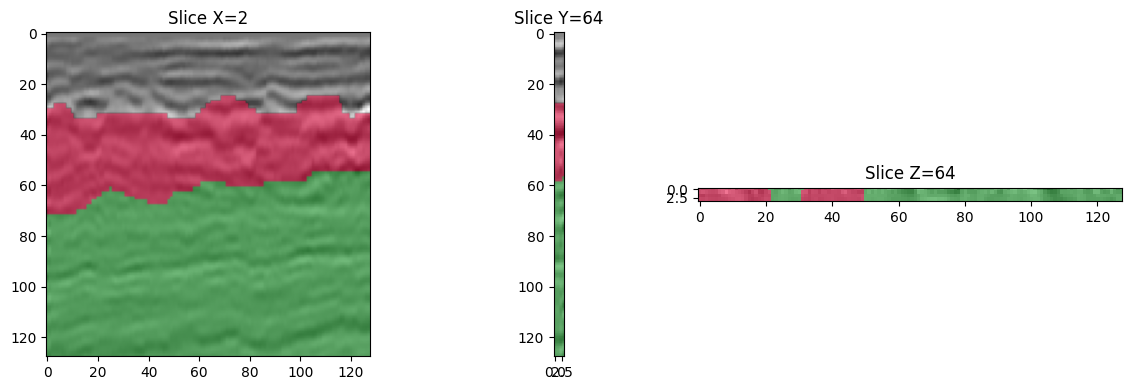

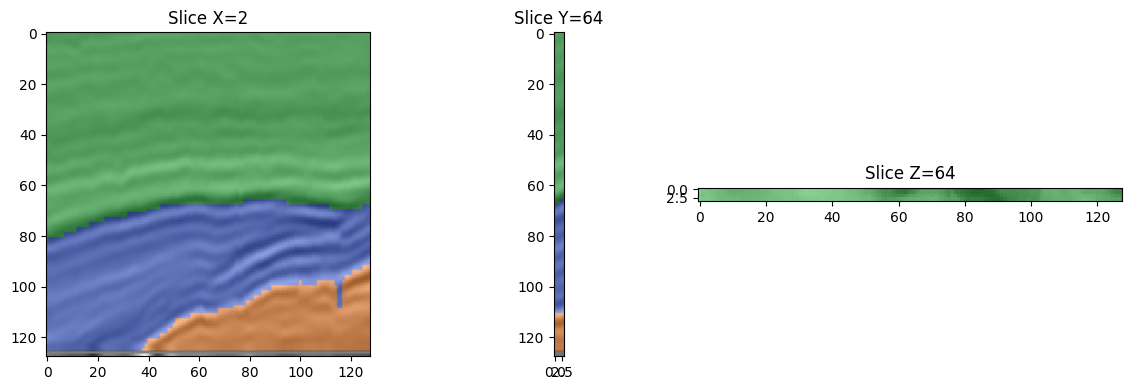

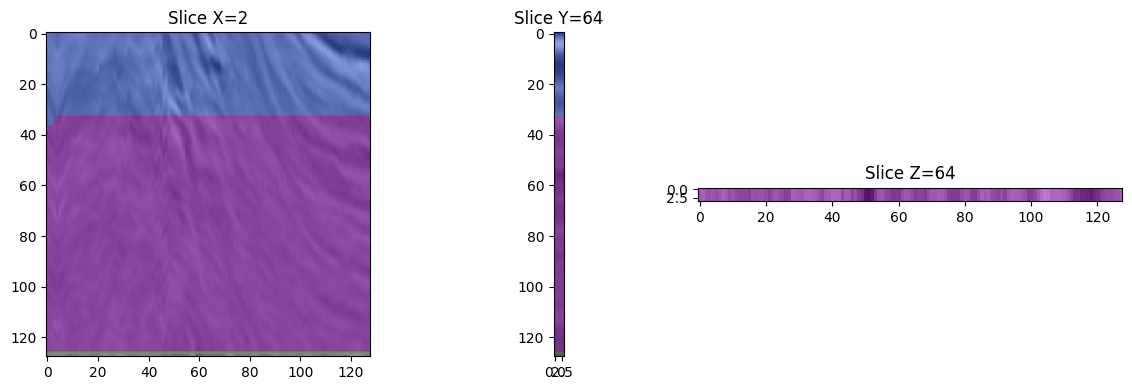

In [92]:
for index in [0, len(df)//2, len(df)-1]:
    row = df.iloc[index]
    showTile(img=np.load(row.img_path), mask=np.load(row.mask_path))